# 02 · Modelagem preditiva (Case NPS, Tech Challenge Fase 1)

**Objetivo:** construir modelos que estimam a satisfação do cliente usando só o que a empresa já sabe antes da pesquisa de NPS, a partir das decisões tomadas na exploração (`01_exploracao_dados.ipynb`).

**Como rodar:** execute as células em ordem. O CSV está em `data/01_raw/desafio_nps_fase_1.csv`.


## Por que esses modelos

A pergunta de negócio tem duas partes, então o projeto usa dois modelos, não um só:

- **"Qual é a nota prevista de NPS?"** pede um número contínuo. Isso é regressão.
- **"Este pedido vai virar um cliente detrator?"** pede uma categoria (sim ou não). Isso é classificação.

**Por que regressão linear, e não um modelo mais complexo (árvore, floresta aleatória etc.):** os coeficientes são diretamente interpretáveis, dá para explicar a um gestor quanto cada variável pesa na nota sem abrir uma caixa-preta. O enunciado pede exatamente esse tipo de entendimento, não o modelo mais sofisticado possível.

**Por que regressão logística para a classificação:** mesma lógica da regressão linear, com coeficientes interpretáveis. Ela também devolve uma probabilidade, não só um rótulo, o que permite ordenar os pedidos por risco em vez de só marcar sim ou não.


## 0. Preparação

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:
CAMINHO_DADOS = '../data/01_raw/desafio_nps_fase_1.csv'

df = pd.read_csv(CAMINHO_DADOS)
df.head()


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


## 1. Quais variáveis entram no modelo?
**Por que importa:** a seção 9 do notebook de exploração mapeou o que correlaciona com a nota de NPS. Aqui essas decisões viram a lista de entrada do modelo.

**Fora do modelo:**
- `csat_internal_score` e `repeat_purchase_30d`: risco de vazamento. A empresa pode medi-los junto ou depois da pesquisa de NPS.
- `customer_region`: o projeto não testou nenhuma codificação de variável categórica, e a seção 7 já mostrou pouca diferença de NPS entre regiões.
- `tempo_real_entrega_dias`: variável derivada só para exploração (seção 10), não usada como entrada.
- `customer_service_contacts`: redundante com `complaints_count`.


In [3]:
print('Correlação complaints_count x customer_service_contacts:', df['complaints_count'].corr(df['customer_service_contacts']).round(3))


Correlação complaints_count x customer_service_contacts: 0.755


As duas colunas andam muito juntas (0,76). Isso confirma a premissa já registrada: `complaints_count` inclui os contatos de atendimento mais outras reclamações. O modelo mantém só `complaints_count`.

**Dentro do modelo, na primeira tentativa:** `order_value`, `items_quantity`, `discount_value`, `payment_installments`, `delivery_time_days`, `delivery_delay_days`, `freight_value`, `delivery_attempts`, `resolution_time_days`, `customer_age`, `customer_tenure_months`, `complaints_count`.


## 2. Primeiro ajuste: modelo com todas as variáveis
**Por que importa:** o `.summary()` do `sm.OLS` mostra a significância estatística de cada variável. A decisão de manter ou cortar vem daqui, não de intuição.


In [4]:
# Todas as variáveis não vazadas, exceto customer_region (sem codificação testada)
features_completo = [
    'order_value', 'items_quantity', 'discount_value', 'payment_installments',
    'delivery_time_days', 'delivery_delay_days', 'freight_value', 'delivery_attempts',
    'resolution_time_days', 'customer_age', 'customer_tenure_months', 'complaints_count'
]

X_completo = df[features_completo].copy()
X_completo['Intercepto'] = 1
Y = df['nps_score']

modelo_completo = sm.OLS(Y, X_completo).fit()
print(modelo_completo.summary())


                            OLS Regression Results                            
Dep. Variable:              nps_score   R-squared:                       0.550
Model:                            OLS   Adj. R-squared:                  0.548
Method:                 Least Squares   F-statistic:                     253.3
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:55:45   Log-Likelihood:                -4849.6
No. Observations:                2500   AIC:                             9725.
Df Residuals:                    2487   BIC:                             9801.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
order_value                0

**Observação:** o modelo completo tem R² de 0,550. Com significância estatística (p < 0,05): `order_value`, `delivery_delay_days`, `freight_value`, `delivery_attempts`, `resolution_time_days` e `complaints_count`. Sem significância: `items_quantity`, `discount_value`, `payment_installments`, `delivery_time_days`, `customer_age`, `customer_tenure_months`.

**Hipótese:** das 6 variáveis significativas, 3 têm coeficiente tão pequeno que não mudam a nota na prática: `order_value` (0,0003), `freight_value` (-0,0065) e `delivery_attempts` (0,094). Multiplicado pelo intervalo inteiro de cada uma, o efeito total fica abaixo de meio ponto de NPS. Com 2.500 linhas, uma variável pode dar estatisticamente significativa sem ter peso real. As outras 3, `delivery_delay_days` (-0,91), `complaints_count` (-0,55) e `resolution_time_days` (-0,14), têm significância e peso grande ao mesmo tempo, e já tinham aparecido como as mais fortes na correlação (seção 9 da exploração).

**Limite da hipótese:** que as variáveis sem significância aqui nunca importam para NPS. Só que, nesta amostra e com este modelo linear, elas não ajudam a explicar a nota.


In [5]:
# Zera a diagonal (correlação de cada variável com ela mesma, sempre 1) antes de pegar o máximo
corr_entradas = df[features_completo].corr().to_numpy().copy()
np.fill_diagonal(corr_entradas, 0)
maior_correlacao = np.abs(corr_entradas).max()

print('Maior correlação entre pares de variáveis de entrada:', round(maior_correlacao, 3))
print()
print('Escala (mínimo e máximo) de cada variável:')
print(df[features_completo].agg(['min', 'max']).T)


Maior correlação entre pares de variáveis de entrada: 0.19

Escala (mínimo e máximo) de cada variável:
                          min      max
order_value              7.76  1983.81
items_quantity           1.00     6.00
discount_value           0.02   230.33
payment_installments     1.00    11.00
delivery_time_days       2.00    14.00
delivery_delay_days      0.00     8.00
freight_value            2.62    76.13
delivery_attempts        1.00     3.00
resolution_time_days     0.00    11.00
customer_age            18.00    69.00
customer_tenure_months   1.00   119.00
complaints_count         0.00    11.00


**Sobre o aviso de multicolinearidade do `.summary()` (condition number 3.900):** o aviso aponta multicolinearidade ou outro problema numérico, sem dizer qual dos dois. A maior correlação entre as 12 variáveis de entrada é 0,19, entre atraso e reclamações, fraca demais para ser multicolinearidade de verdade. O problema real é a escala: `order_value` chega a 1.983 e `customer_tenure_months` a 119, enquanto `delivery_attempts` vai só de 1 a 3. Misturar números tão desproporcionais deixa o cálculo do OLS numericamente instável. Isso gera o aviso, não variáveis competindo pela mesma informação.

Os coeficientes das 3 variáveis que pesam de verdade (`delivery_delay_days`, `complaints_count`, `resolution_time_days`) ficam quase idênticos no modelo completo e no modelo reduzido (próxima seção), com diferença só na terceira casa decimal. Se a instabilidade numérica estivesse distorcendo o ajuste, essa diferença apareceria. Como não aparece, o aviso não compromete as conclusões do modelo completo.


## 3. Modelo reduzido: só o que pesa de verdade
**Decisão:** refazer o ajuste com só `delivery_delay_days`, `complaints_count` e `resolution_time_days`, as três variáveis com significância e efeito prático relevante.


In [6]:
# Só as 3 variáveis com significância e efeito prático (decisão da seção 2)
features_reduzido = ['delivery_delay_days', 'complaints_count', 'resolution_time_days']

X_reduzido = df[features_reduzido].copy()
X_reduzido['Intercepto'] = 1

modelo_reduzido = sm.OLS(Y, X_reduzido).fit()
print(modelo_reduzido.summary())


                            OLS Regression Results                            
Dep. Variable:              nps_score   R-squared:                       0.546
Model:                            OLS   Adj. R-squared:                  0.545
Method:                 Least Squares   F-statistic:                     1001.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:55:45   Log-Likelihood:                -4860.6
No. Observations:                2500   AIC:                             9729.
Df Residuals:                    2496   BIC:                             9753.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
delivery_delay_days     -0.9067 

**Observação:** o R² cai de 0,550 para 0,546, com 3 variáveis em vez de 12. O condition number cai de 3.900 para 25,1.

**Hipótese:** tirar as outras 9 variáveis custa 0,004 de R², quase nada. Elas eram ruído nesta amostra. A queda no condition number confirma que o problema era a diferença de escala entre as variáveis descartadas. As 3 que restaram (`delivery_delay_days` 0-8, `complaints_count` 0-11, `resolution_time_days` 0-11) têm escalas parecidas entre si. O modelo reduzido explica tanto quanto o completo, com menos variáveis e mais fácil de justificar.

**Decisão final:** o modelo preditivo usa `delivery_delay_days`, `complaints_count` e `resolution_time_days` como entrada.


## 4. Separação entre treino e teste
**Por que importa:** o modelo precisa ser avaliado em dados que ele não viu durante o ajuste, para mostrar se ele generaliza. Separação de 80% para treino e 20% para teste, com semente fixa (`random_state=42`).


In [7]:
X = df[features_reduzido]
Y = df['nps_score']

# 80% treino, 20% teste, semente fixa para reproduzir a mesma divisão
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

print('Treino:', X_train.shape)
print('Teste:', X_test.shape)


Treino: (2000, 3)
Teste: (500, 3)


## 5. Ajuste do modelo final
**Por que importa:** o modelo é ajustado só com a parte de treino. Ele nunca vê os dados de teste.


In [8]:
# Ajusta só com o treino, nunca vê os dados de teste
modelo_final = LinearRegression()
modelo_final.fit(X_train, y_train)

print('Coeficientes:', dict(zip(features_reduzido, modelo_final.coef_.round(4))))
print('Intercepto:', round(modelo_final.intercept_, 4))


Coeficientes: {'delivery_delay_days': np.float64(-0.8912), 'complaints_count': np.float64(-0.5663), 'resolution_time_days': np.float64(-0.1455)}
Intercepto: 9.4697


## 6. Avaliação no treino e no teste
**Por que importa:** comparar o erro no treino com o erro no teste mostra se o modelo decorou os dados ou se generaliza.


In [9]:
pred_train = modelo_final.predict(X_train)
pred_test = modelo_final.predict(X_test)

for nome, y_real, y_pred in [('Treino', y_train, pred_train), ('Teste', y_test, pred_test)]:
    mae = mean_absolute_error(y_real, y_pred)
    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_real, y_pred)
    print(f'{nome}: MAE={mae:.3f}  MSE={mse:.3f}  RMSE={rmse:.3f}  R2={r2:.3f}')


Treino: MAE=1.338  MSE=2.864  RMSE=1.692  R2=0.545
Teste: MAE=1.340  MSE=2.847  RMSE=1.687  R2=0.550


In [10]:
for nome, pred in [('treino', pred_train), ('teste', pred_test)]:
    abaixo_de_zero = (pred < 0).sum()
    acima_de_dez = (pred > 10).sum()
    print(f'{nome}: {abaixo_de_zero} previsões abaixo de 0, {acima_de_dez} acima de 10, mínimo {pred.min():.2f}, máximo {pred.max():.2f}')


treino: 19 previsões abaixo de 0, 0 acima de 10, mínimo -2.32, máximo 9.47
teste: 7 previsões abaixo de 0, 0 acima de 10, mínimo -1.09, máximo 9.18


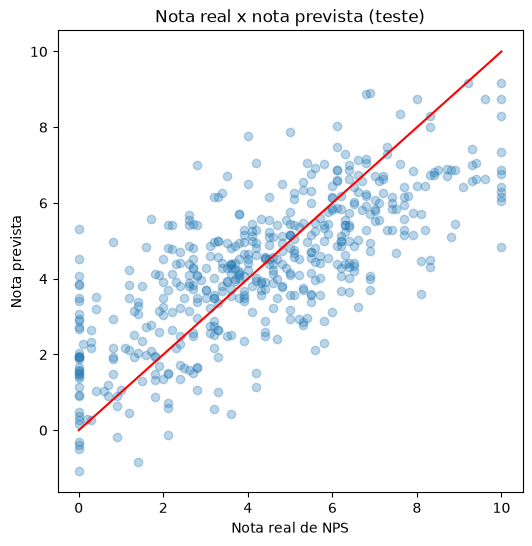

In [11]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_test, alpha=0.3)
plt.plot([0, 10], [0, 10], color='red')
plt.title('Nota real x nota prevista (teste)')
plt.xlabel('Nota real de NPS')
plt.ylabel('Nota prevista')
plt.savefig('../reports/figures/real_vs_previsto.png', dpi=150, bbox_inches='tight')
plt.show()


**Observação:** no treino, MAE 1,338, MSE 2,864, RMSE 1,692, R² 0,545. No teste, MAE 1,340, MSE 2,847, RMSE 1,687, R² 0,550. As métricas de treino e teste ficam praticamente iguais.

**Hipótese:** o modelo não decorou os dados de treino, ele generaliza para dados novos. O erro médio de cerca de 1,34 ponto, numa escala de 0 a 10, é o custo de usar só 3 variáveis operacionais simples. O R² de 0,55 significa que o modelo explica um pouco mais da metade da variação da nota. A outra metade vem de fatores que a base não tem: perfil do cliente, expectativa individual, concorrência.

**Limitação da regressão linear:** o modelo prevê valores fora da faixa válida de NPS (0 a 10) em alguns casos: 19 das 2.000 previsões de treino e 7 das 500 de teste ficam abaixo de 0, com mínimo de -2,32. Isso acontece porque a regressão linear não conhece os limites da escala, ela extrapola a reta mesmo onde a nota real não pode existir. Previsões negativas devem ser lidas como "nota muito baixa", não como um valor literal.

**Limite da hipótese:** que reduzir o atraso ou as reclamações causa uma nota melhor. O modelo mostra associação, não causa, o mesmo cuidado já registrado na seção 9 da exploração.


## 7. Alternativa: classificar detratores
**Por que importa:** o enunciado permite regressão ou classificação. Em vez de estimar a nota exata, o modelo de classificação responde uma pergunta mais direta para a operação: este pedido vai virar um cliente detrator ou não?


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, confusion_matrix

nota_arredondada = df['nps_score'].round()
y_detrator = (nota_arredondada <= 6).astype(int)

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X, y_detrator, test_size=0.2, random_state=42
)

print('Proporção de detratores no teste:', round(y_test_cls.mean(), 3))


Proporção de detratores no teste: 0.812


Mesmas 3 variáveis de entrada e a mesma separação 80/20 do modelo de regressão, trocando só o alvo: em vez da nota contínua, um rótulo binário (1 para detrator, 0 para passivo ou promotor).


In [13]:
modelo_classificacao = LogisticRegression()
modelo_classificacao.fit(X_train_cls, y_train_cls)

pred_cls = modelo_classificacao.predict(X_test_cls)
proba_cls = modelo_classificacao.predict_proba(X_test_cls)[:, 1]

print('Acurácia:', round(accuracy_score(y_test_cls, pred_cls), 3))
print('Recall:', round(recall_score(y_test_cls, pred_cls), 3))
print('ROC-AUC:', round(roc_auc_score(y_test_cls, proba_cls), 3))
print()
print('Matriz de confusão (linhas: real, colunas: previsto):')
print(confusion_matrix(y_test_cls, pred_cls))


Acurácia: 0.858
Recall: 0.941
ROC-AUC: 0.882

Matriz de confusão (linhas: real, colunas: previsto):
[[ 47  47]
 [ 24 382]]


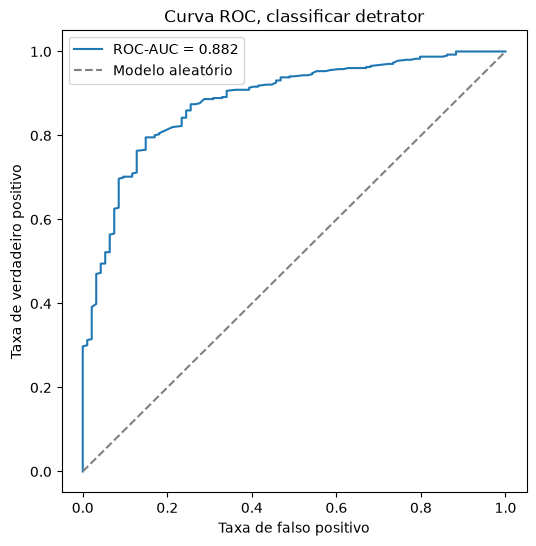

In [14]:
from sklearn.metrics import roc_curve

fpr, tpr, limiares = roc_curve(y_test_cls, proba_cls)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc_score(y_test_cls, proba_cls):.3f}')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Modelo aleatório')
plt.title('Curva ROC, classificar detrator')
plt.xlabel('Taxa de falso positivo')
plt.ylabel('Taxa de verdadeiro positivo')
plt.legend()
plt.savefig('../reports/figures/curva_roc.png', dpi=150, bbox_inches='tight')
plt.show()


A curva mostra a troca entre acertar mais detratores (eixo vertical) e errar mais não detratores (eixo horizontal), em cada ponto de corte possível do modelo. Quanto mais a curva sobe antes de ir para a direita, melhor o modelo separa as duas classes. A linha cinza é o que um modelo aleatório faria. O ROC-AUC de 0,882 é a área sob a curva azul, bem acima da linha de base.


**Observação:** acurácia de 0,858, recall de 0,941, ROC-AUC de 0,882. Na matriz de confusão, de 429 detratores reais no teste, o modelo acerta 382 e erra 47 (deixa passar). Dos 94 não detratores, acerta 47 e erra 47.

**Hipótese:** o modelo é bom para não deixar passar detratores (recall alto), o que importa para a operação, já que o custo de não agir com um detrator costuma ser maior que o custo de uma ação desnecessária com um cliente satisfeito. O ROC-AUC de 0,882 indica boa separação entre as duas classes.

**Limite da hipótese:** a base de teste tem bem mais detratores (81%) que as outras classes, então a acurácia sozinha não seria uma boa medida, por isso o recall e o ROC-AUC pesam mais na leitura. Os mesmos cuidados do modelo de regressão valem aqui: associação, não causa, e sem garantia fora desta base.


## 8. Resumo e como a empresa pode usar isso

**O que o modelo faz:** a partir de 3 números que a empresa já tem assim que o pedido é entregue e atendido, dias de atraso, reclamações e dias para resolver, estima a nota de NPS antes de aplicar a pesquisa.

**Como usar na prática, de forma reativa:** rode o modelo nos pedidos recém-entregues e sinalize os que têm nota prevista baixa, antes do cliente responder a pesquisa. Isso dá à empresa uma janela para agir, por exemplo contato proativo, pedido de desculpas, compensação, em vez de descobrir o problema só depois que o NPS já foi respondido.

**Onde investir, de forma preventiva:** o atraso na entrega é a variável mais associada a notas baixas, com o maior coeficiente dos três (-0,91). Isso aponta a logística de entrega como a área operacional mais promissora para investigação e investimento, à frente de atendimento e tempo de resolução. Essa prioridade vem dos dados, não é uma garantia: o modelo mostra associação, não prova que reduzir o atraso causa uma nota melhor.

**Próximo passo sugerido para a empresa, fora do escopo deste projeto:** confirmar se reduzir o atraso melhora a nota exige um teste controlado (teste A/B), comparando um grupo de pedidos com alguma intervenção na entrega contra um grupo sem intervenção, nas mesmas condições. Esta análise não inclui esse experimento, porque a base é um retrato histórico dos pedidos, sem grupos de teste e controle.

**Limitações:**
- O modelo explica 55% da variação da nota. Não dá para prever a nota com precisão individual, só a tendência.
- As variáveis fora do modelo, perfil do cliente, valor do pedido, forma de pagamento, não ajudaram a explicar o NPS nesta base, mas podem importar em outro contexto.
- O modelo pode prever notas fora da faixa válida (0 a 10). Isso aconteceu em cerca de 1% dos pedidos nesta base. Trate uma previsão negativa como "nota muito baixa", não como um valor literal.
- Correlação não é causa. O modelo aponta onde agir, não garante que agir ali resolve o problema.
